# Results: how well each arm does

**What this answers:** How the arms compare on both ranking views, calibration, and the pre-declared contrasts.

**What it reads:** The baseline tables written by the evaluation pipeline.

**What to expect:** A headline table, the two views, reliability, the contrasts with verdicts, and the place-only diagnostics.

**Provisional values.** Every pooled five-fold value, every fold-2023 value, and every probability of detection, false alarm ratio and critical success index in this notebook is provisional. Three limits (`docs/limitations.md`): (1) fold-2023 numbers use soil-moisture anomaly inputs whose norm includes later 2023 weather, and the same norm covers 2021 and 2022 rows in the pooled tables; (2) the settings of every model were chosen on scored rows (validation years 2021-2024 for the baseline); (3) the fold-2023 alert threshold was chosen on fold-2024 labels. The outputs below were produced before this note and are unchanged; nothing is removed, and corrected numbers will replace them when they exist.

Load the reporting helpers.

In [1]:
from wildfire.reporting import results
from IPython.display import display

**Headline table.** Both ranking views for every arm, plus average precision, log loss, Brier score and top-k capture. Metrics are pooled over the validation years 2021 to 2025; 2025 is a development fold, not an untouched test. Network rows are the mean over ten seeds.

In [2]:
display(results.headline_table())

,arm,auc_spatial_within_day,auc_temporal_within_cell,ap,log_loss,brier,capture_1pct,lift_1pct,capture_5pct,lift_5pct
0,climatology_cell,0.6537,0.5909,0.0951,0.0889,0.0179,0.0336,3.3647,0.1435,2.8698
1,landcover_season,0.5532,0.5557,0.0682,0.0907,0.0180,0.0150,1.4982,0.0845,1.6899
2,fwi_season,0.5536,0.6441,0.0851,0.0886,0.0180,0.0259,2.5938,0.1093,2.1851
3,logistic_weather_static@tabular,0.6102,0.6783,0.0976,0.0870,0.0179,0.0272,2.7161,0.1243,2.4852
4,logistic_weather_static@enriched,0.7332,0.7469,0.1634,0.0818,0.0177,0.0517,5.1656,0.2050,4.0990
5,logistic_with_burn@tabular,0.6300,0.6745,0.1038,0.0868,0.0179,0.0312,3.1198,0.1350,2.7005
6,logistic_with_burn@enriched,0.7338,0.7465,0.1637,0.0818,0.0177,0.0517,5.1706,0.2054,4.1079
7,boosting@tabular,0.7688,0.7562,0.1909,0.0803,0.0174,0.0665,6.6509,0.2171,4.3411
8,boosting@enriched,0.8110,0.7896,0.2261,0.0768,0.0172,0.0751,7.5062,0.2490,4.9797
9,tabular_network@tabular,0.7393,0.7676,0.1694,0.0825,0.0176,0.0550,5.4973,0.2057,4.1148


**The two views.** Spatial (which cells) against temporal (which days). A model can be good at one and weak at the other.

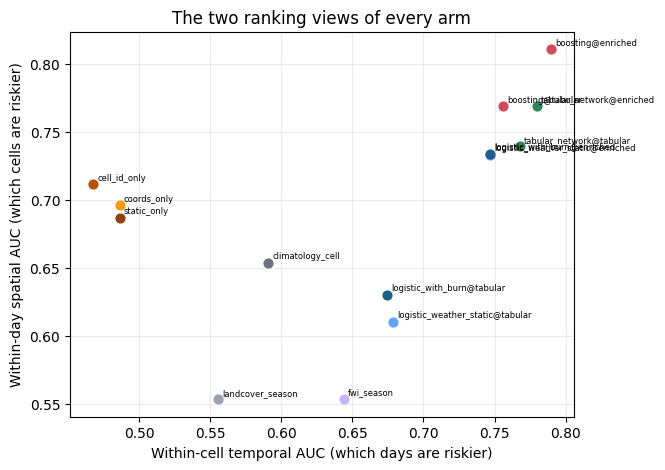

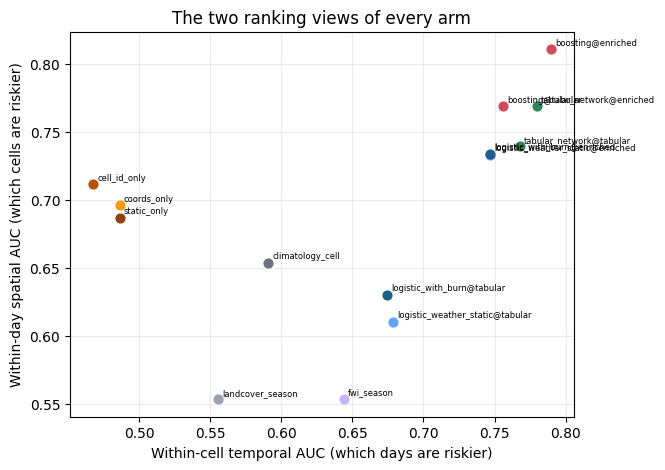

In [3]:
results.plot_two_views()

**Reliability.** Do predicted probabilities match observed rates?

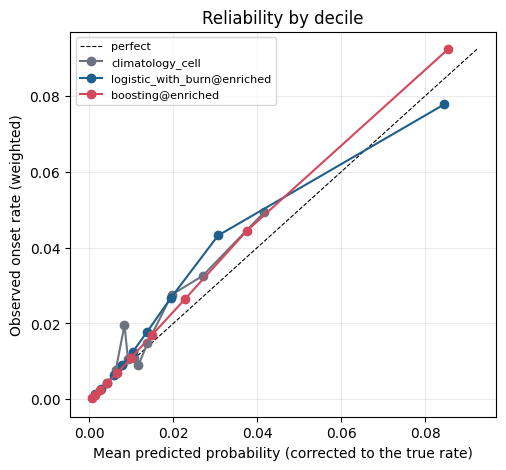

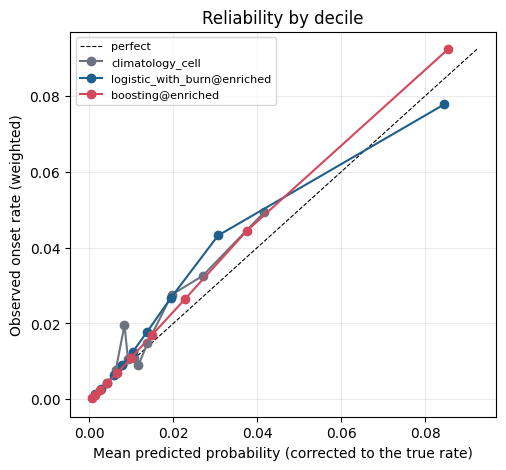

In [4]:
results.plot_reliability()

**Pre-declared contrasts.** Every contrast is shown, including ones that fail. PASS needs a gain of at least 0.010 in AP with a clear interval.

In [5]:
display(results.contrast_table())

,contrast,arm,reference,delta_ap,ap_lo99,ap_hi99,mde,worst_state,worst_state_delta_ap,verdict
0,enriched_boosting_vs_tabular_boosting,boosting@enriched,boosting@tabular,0.0352,0.0251,0.0441,0.0127,JH,0.0074,INCONCLUSIVE
1,enriched_boosting_vs_enriched_logistic,boosting@enriched,logistic_with_burn@enriched,0.0623,0.0433,0.0812,0.0254,JH,0.0380,INCONCLUSIVE


**Network seeds against enriched boosting.** Ten seeds, each compared with boosting.

In [6]:
display(results.network_seed_contrasts())

,delta_ap,mde,verdict
arm,,,
tabular_network@enriched#0,-0.0253,0.0263,INCONCLUSIVE
tabular_network@enriched#1,-0.0266,0.0275,INCONCLUSIVE
tabular_network@enriched#2,-0.0291,0.0264,INCONCLUSIVE
tabular_network@enriched#3,-0.0279,0.0302,INCONCLUSIVE
tabular_network@enriched#4,-0.0297,0.0275,INCONCLUSIVE
tabular_network@enriched#5,-0.0325,0.0307,INCONCLUSIVE
tabular_network@enriched#6,-0.0269,0.0282,INCONCLUSIVE
tabular_network@enriched#7,-0.0305,0.0289,INCONCLUSIVE
tabular_network@enriched#8,-0.0245,0.0263,INCONCLUSIVE


**Every arm against the climatology.**

In [7]:
display(results.versus_climatology())

,arm,delta_ap,ap_lo99,ap_hi99,mde,verdict
0,landcover_season,-0.0269,-0.0402,-0.0129,0.0176,INCONCLUSIVE
1,fwi_season,-0.0100,-0.0238,0.0028,0.0176,INCONCLUSIVE
2,logistic_weather_static@tabular,0.0025,-0.0111,0.0148,0.0170,INCONCLUSIVE
3,logistic_weather_static@enriched,0.0683,0.0513,0.0820,0.0198,INCONCLUSIVE
4,logistic_with_burn@tabular,0.0086,-0.0050,0.0214,0.0168,INCONCLUSIVE
5,logistic_with_burn@enriched,0.0686,0.0516,0.0825,0.0199,INCONCLUSIVE
6,boosting@tabular,0.0958,0.0718,0.1160,0.0296,INCONCLUSIVE
7,boosting@enriched,0.1310,0.1064,0.1509,0.0307,INCONCLUSIVE
8,coords_only,-0.0085,-0.0228,0.0043,0.0185,INCONCLUSIVE
9,cell_id_only,0.0056,-0.0096,0.0161,0.0179,INCONCLUSIVE


**Place-only diagnostics.** How much a model knows from the cell alone.

In [8]:
display(results.identity_table())

,arm,auc_spatial_within_day,auc_temporal_within_cell,ap
0,coords_only,0.6960,0.4865,0.0866
1,cell_id_only,0.7115,0.4676,0.1007
2,static_only,0.6870,0.4864,0.0896
3,boosting@enriched,0.8110,0.7896,0.2261
4,climatology_cell,0.6537,0.5909,0.0951


**Findings.** Sentences built from the tables above.

In [9]:
display(results.key_findings())

,finding
0,Best within-day spatial AUC: boosting@enriched...
1,Best within-cell temporal AUC: boosting@enrich...
2,The climatology scores 0.654 spatial and 0.591...
3,Pre-declared contrasts (a)-(c): 2 INCONCLUSIVE.
4,The cell's own onset rate alone gives spatial ...


## What this shows

The findings table at the end is built from the saved tables each time the notebook runs; read it with the contrast table, where a contrast only passes if its interval is clear and its minimum detectable effect is small enough.

## What it does not show

It does not show skill in new states (next notebook), nor causal effects of any input.